# imports



In [2]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes
from sklearn.datasets import load_breast_cancer
from sklearn.datasets import fetch_openml

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error as MSE

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.feature_selection import RFE
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import f_regression
from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import f_classif
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectFromModel

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR
from sklearn.tree import plot_tree

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from sklearn.utils.class_weight import compute_class_weight

from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram



from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import BorderlineSMOTE

from imblearn.under_sampling import RandomUnderSampler
from imblearn.under_sampling import NearMiss
from imblearn.under_sampling import TomekLinks
from imblearn.under_sampling import EditedNearestNeighbours



from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

#1. Для придания смысла кластерам выведите примеры точек выборки для каждого кластера. Сделайте вывод, чем они отличаются.

In [52]:
df = pd.read_csv('mall_customers_clustering.csv', index_col=0)
df.head()
x = df.drop(["CustomerID"], axis=1)
X = pd.get_dummies(x)
scaler = SC().fit(X)
X_scaled = scaler.transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()


kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
X_scaled['Cluster'] = clusters

for cluster in sorted(X_scaled['Cluster'].unique()):
    print(f"\nПримеры точек кластера {cluster}:")
    print(X_scaled[X_scaled['Cluster'] == cluster].head(10))



Примеры точек кластера 0:
         Age    Income     Score  Genre_Female  Genre_Male  Cluster
8   1.804932 -1.586321 -1.832378     -1.128152    1.128152        0
10  2.020232 -1.586321 -1.405340     -1.128152    1.128152        0
14 -0.132768 -1.548152 -1.444162     -1.128152    1.128152        0
18  0.943732 -1.433644 -0.823017     -1.128152    1.128152        0
30  1.517865 -1.166458 -1.793556     -1.128152    1.128152        0
32  1.015499 -1.051949 -1.793556     -1.128152    1.128152        0
42  0.656665 -0.822933 -0.551266     -1.128152    1.128152        0
53  1.446099 -0.670255  0.380451     -1.128152    1.128152        0
55  0.584899 -0.670255 -0.357158     -1.128152    1.128152        0
57  2.163766 -0.632086 -0.163051     -1.128152    1.128152        0

Примеры точек кластера 1:
         Age    Income     Score  Genre_Female  Genre_Male  Cluster
3  -1.137502 -1.700830  1.040418      0.886405   -0.886405        1
5  -1.209269 -1.662660  1.001596      0.886405   -0.886405    

Кластеры 1 и 2 были отделены по Genre_Female, 0,3,4 по Genre_Male

Income в кластере 3 положительный, в то время как в остальных он отрицательный

Score кластера 1 и 3 положительный, остальных отрицательный

Age кластера 1 и 4 строго отрицательный

#2. Используйте для визуализации результатов кластеризации другие пары признаков. Сделайте вывод о зависимости кластеризации от признаков.

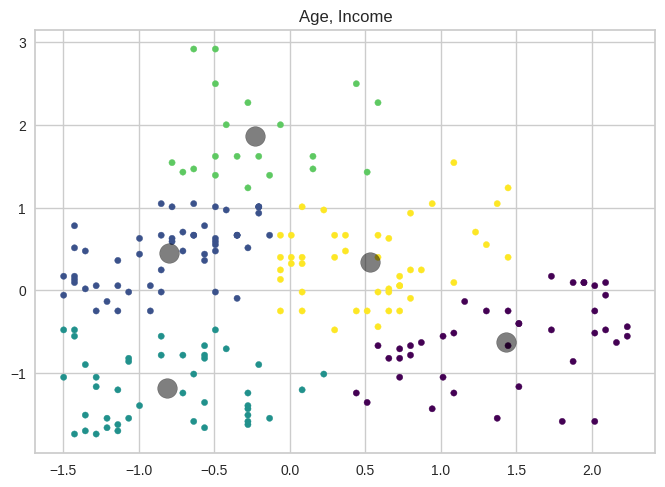

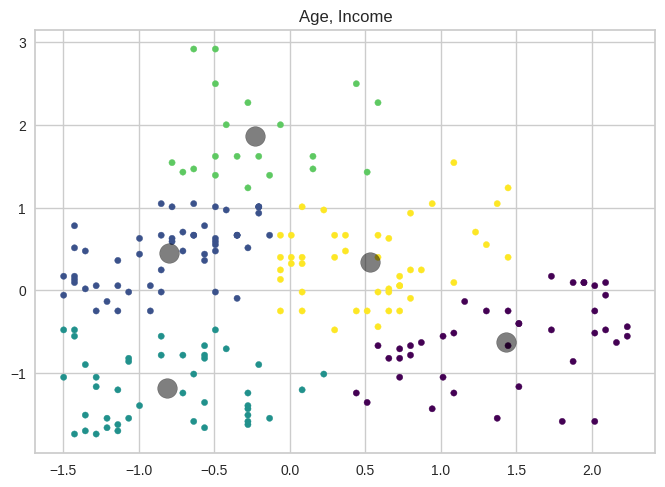

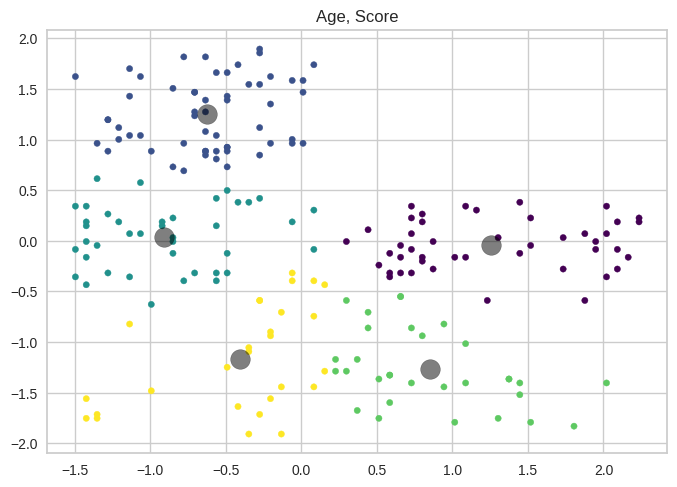

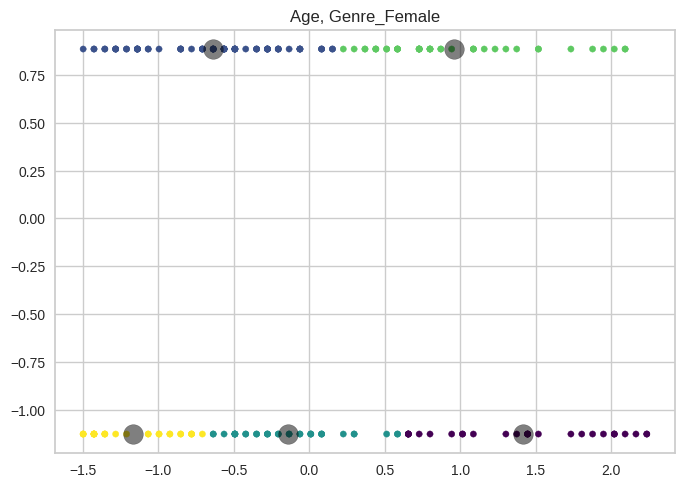

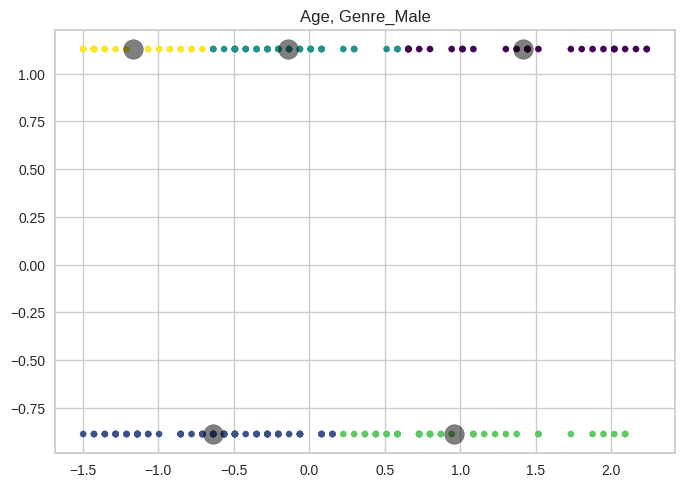

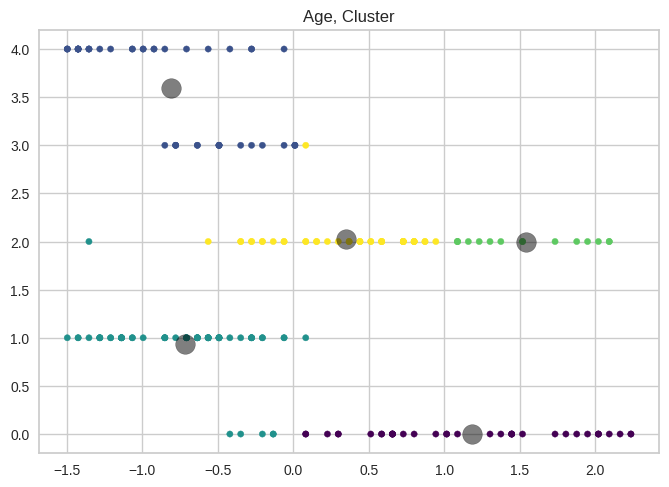

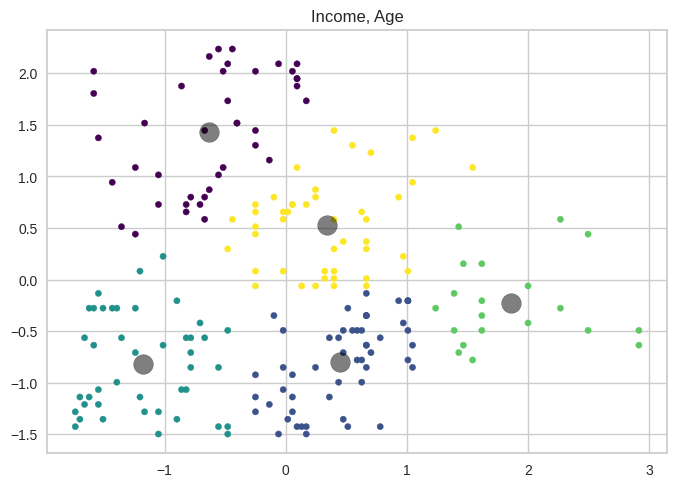

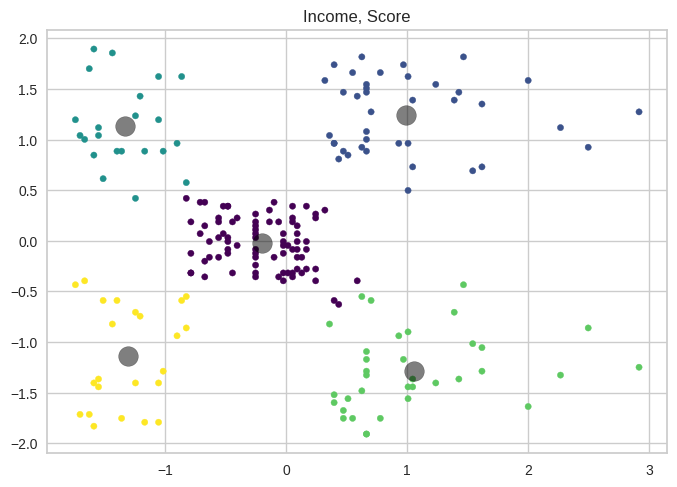

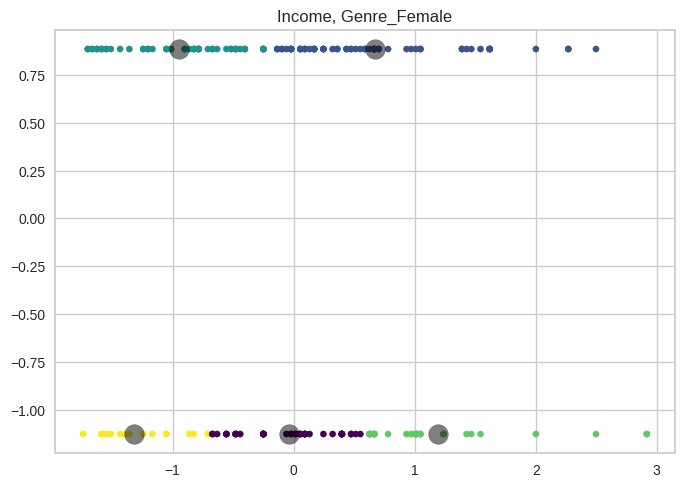

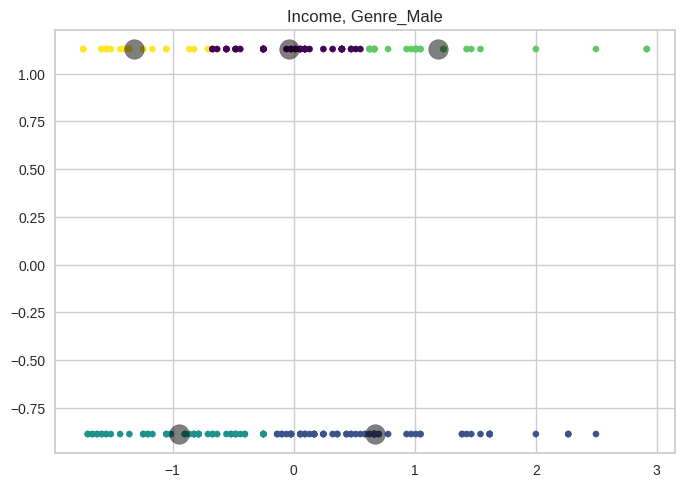

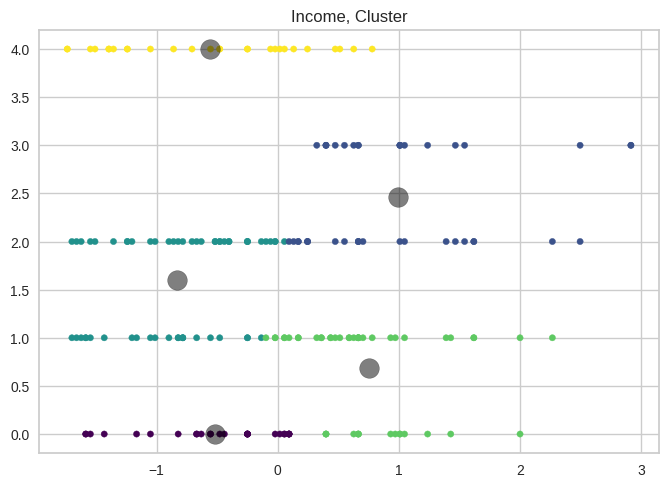

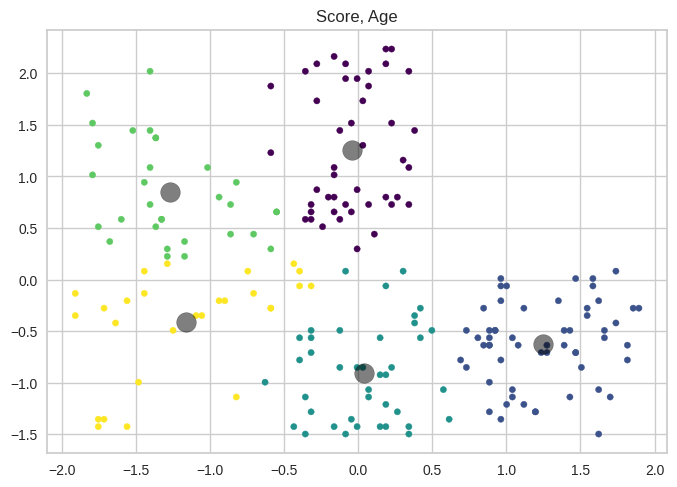

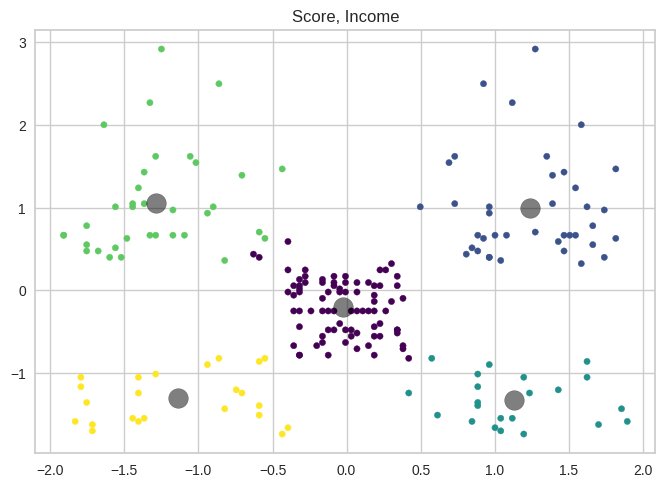

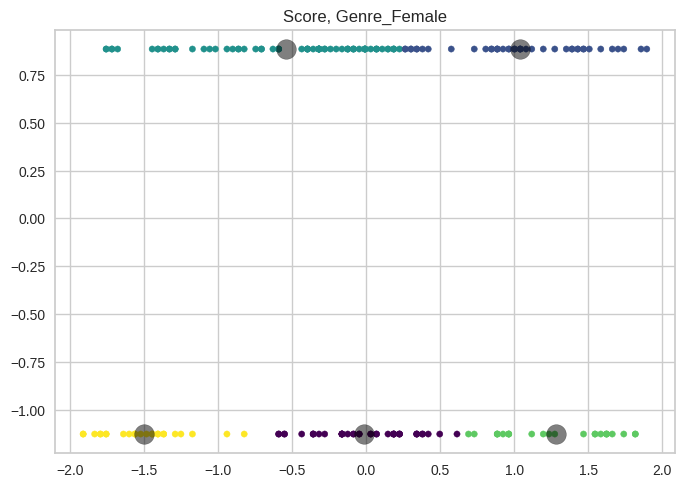

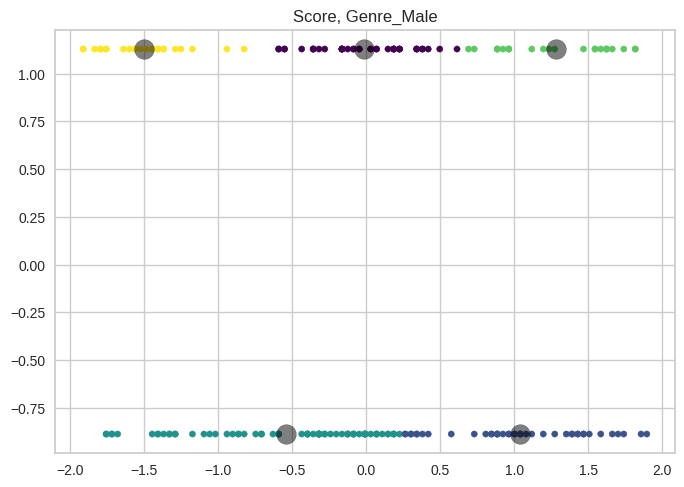

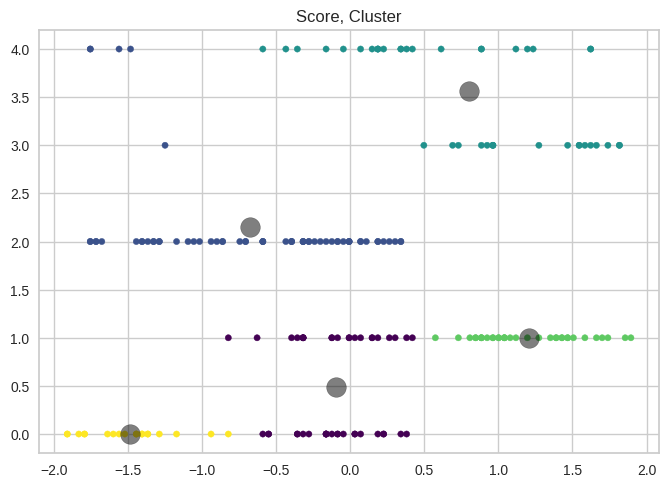

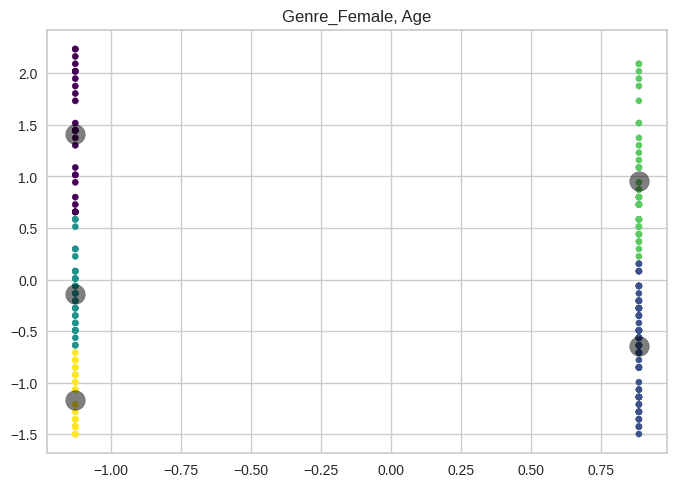

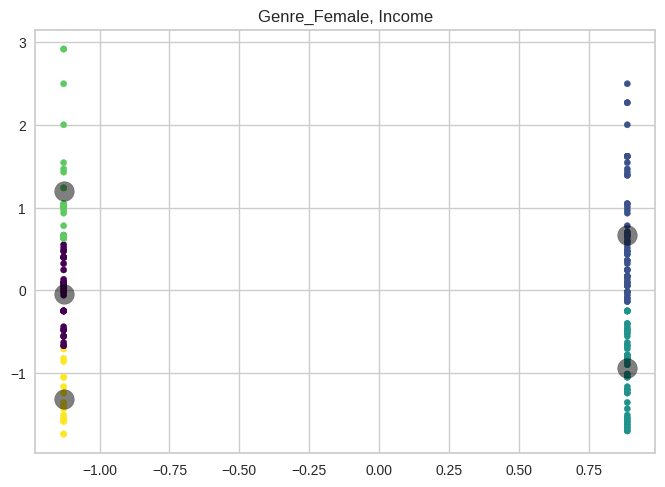

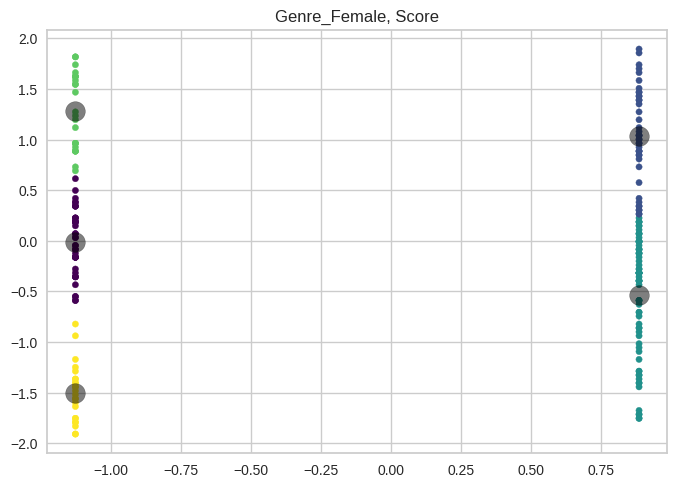

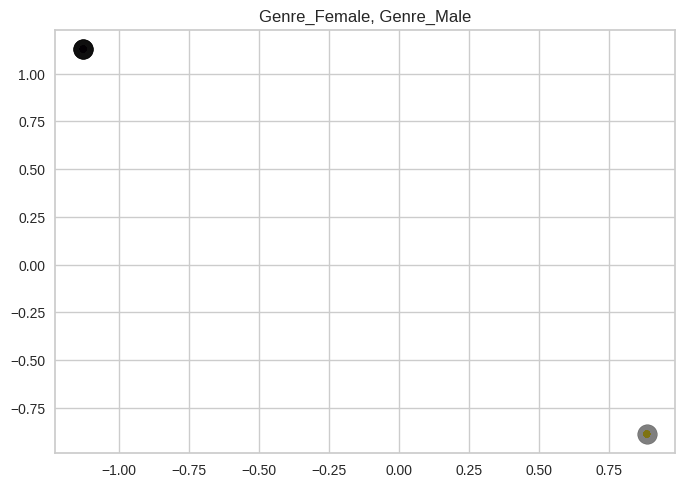

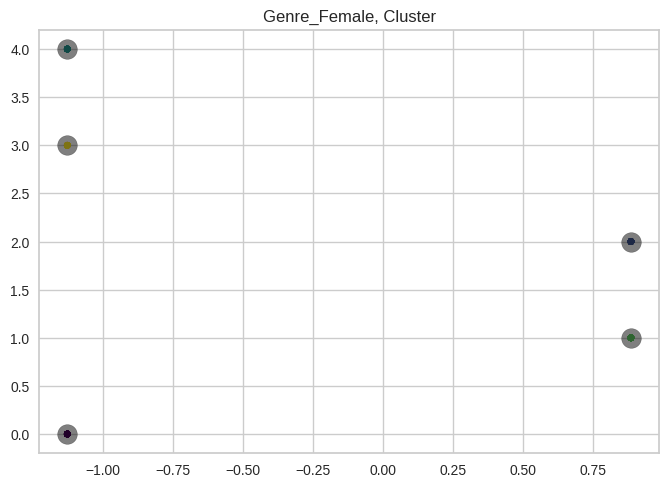

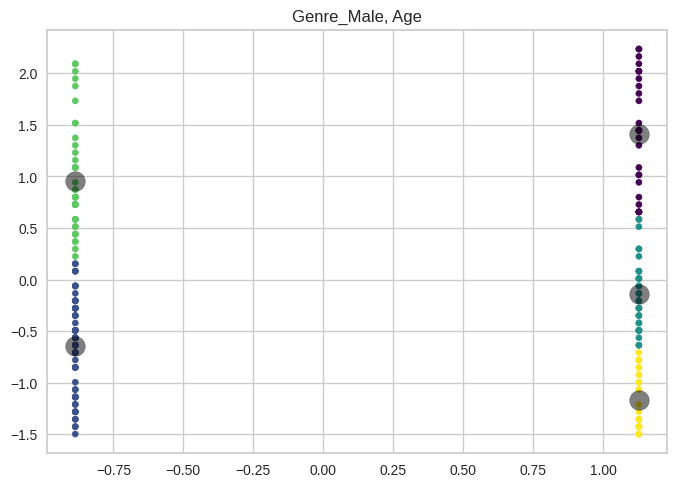

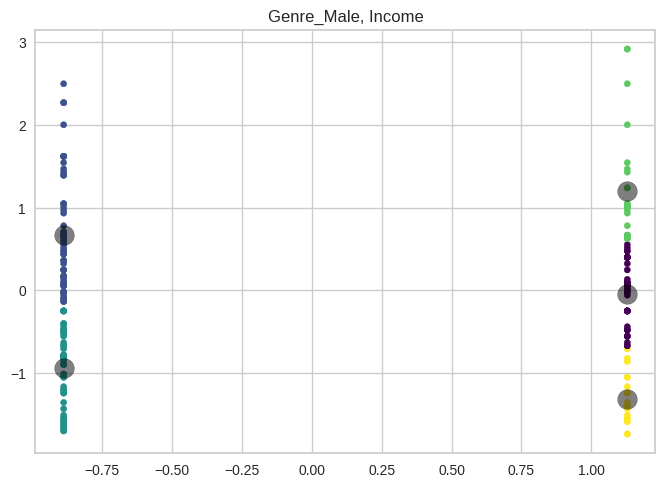

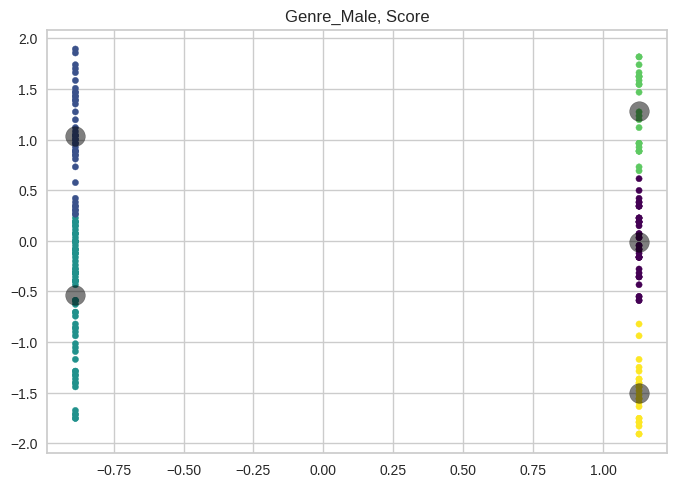

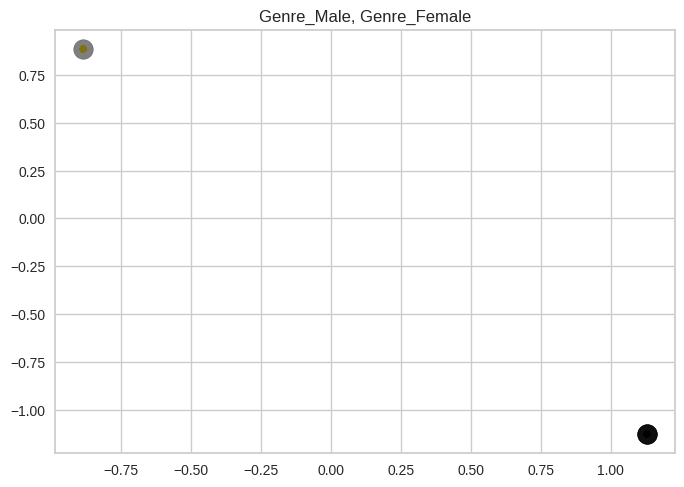

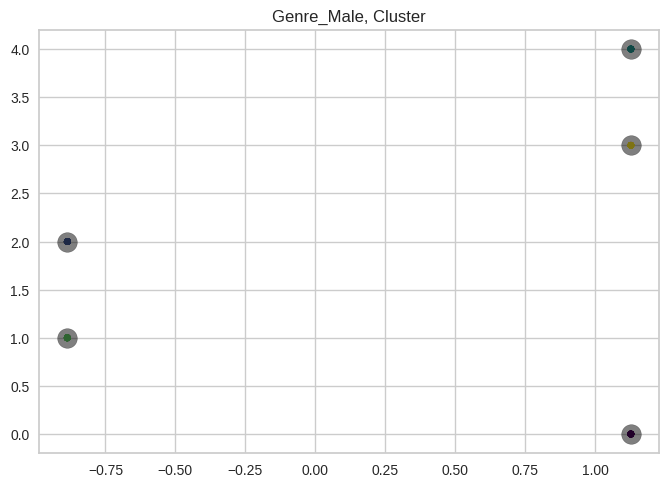

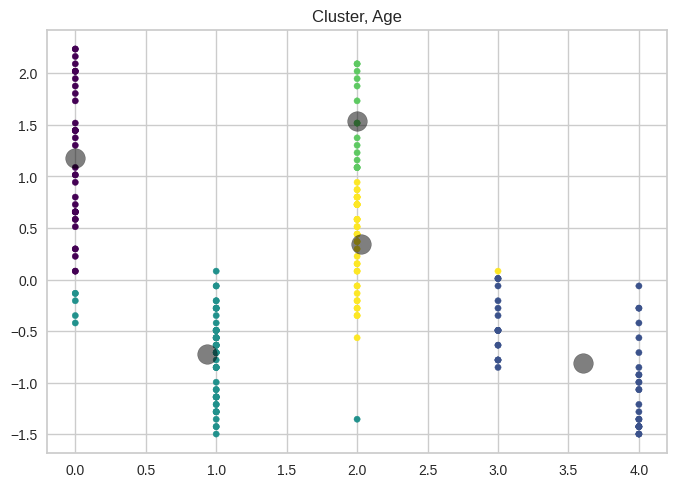

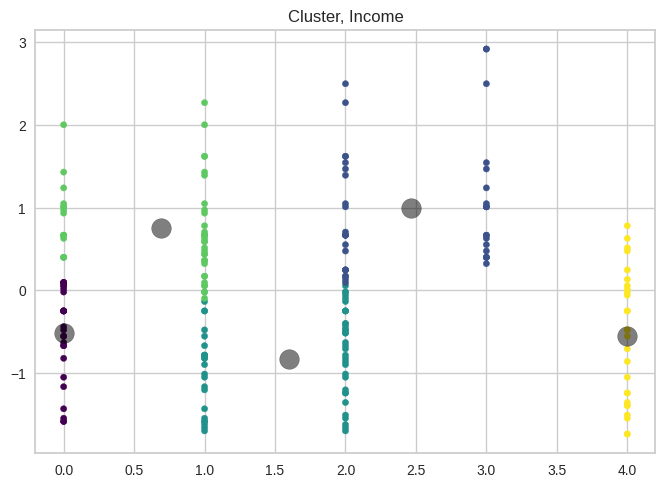

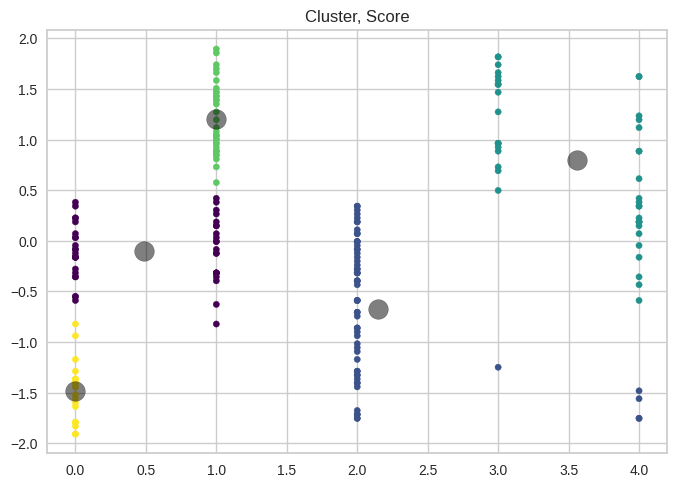

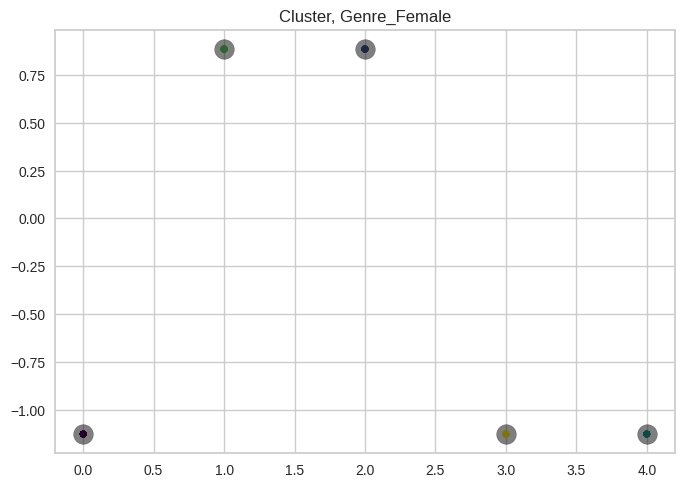

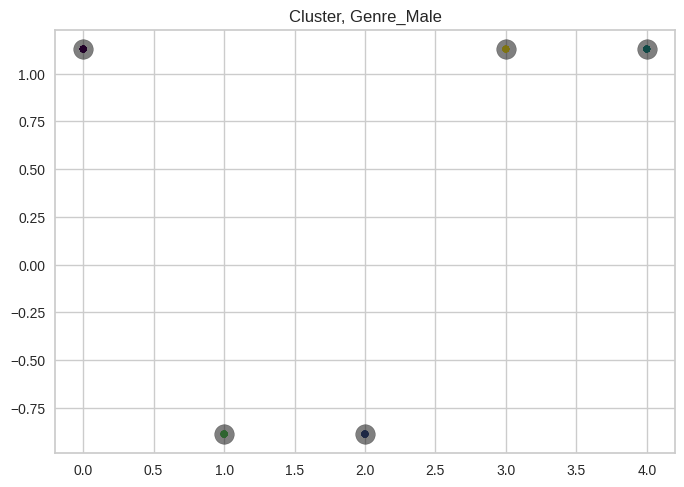

In [53]:
X_flat = X_scaled.drop([ "Score", 'Genre_Female',"Genre_Male", 'Cluster'], axis=1)
X_flat.head()

kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X_flat)
#X_flat['Cluster'] = clusters

plt.scatter(X_flat.Age, X_flat.Income, c=kmeans.labels_, s=20, cmap='viridis')
centers = kmeans.cluster_centers_
#print(centers)
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.title('Age, Income')
plt.show()

def clustering(df,a,b):
  df1 = df[[a,b]]
  kmeans = KMeans(n_clusters=5, random_state=42)
  clusters = kmeans.fit_predict(df1)

  plt.scatter(df1[a], df1[b], c=kmeans.labels_, s=20, cmap='viridis')
  centers = kmeans.cluster_centers_
  #print(centers)
  plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
  plt.title(f'{a}, {b}')
  plt.show()


for i in X_scaled.columns:
  for j in X_scaled.columns:
    if i == j:
      continue
    clustering(X_scaled,i,j)

Вывод:

 Парами признаков, наиболее подходящими для кластеризации оказались:

 Age,Score - визуально можно заметить 2 кластера

 Score, Male и Score, Female явно видны 5 кластеров




#3. Повторите весь анализ для другого датасета - кластеризации кредитных карт.

In [51]:
df = pd.read_csv('credit_card_clustering.csv', index_col=0)
display(df.head())
x = df.dropna()
X = pd.get_dummies(x)
scaler = SC().fit(X)
X_scaled = scaler.transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

def clustering(df,a,b):
  df1 = df[[a,b]]
  kmeans = KMeans(n_clusters=5, random_state=42)
  clusters = kmeans.fit_predict(df1)

  plt.scatter(df1[a], df1[b], c=kmeans.labels_, s=20, cmap='viridis')
  centers = kmeans.cluster_centers_
  #print(centers)
  plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
  plt.title(f'{a}, {b}')
  plt.show()

def inertia(df, l):
  wcss = []
  for i in range(1,l):
  	k_means = KMeans(n_clusters=i,random_state=42)
  	k_means.fit(df)
  	wcss.append(k_means.inertia_)
  plt.plot(range(1,l),wcss)
  plt.xticks(range(1,l))
  plt.show()

# График локтя
inertia(X_scaled,30)

#Заметим, что оптимальное количество признаков - 10, по тому как на графике с 11 по 12 график стационарен

# Выведем кластеризацию попарно для каждых двух колонок и посмотрим
for i in X_scaled.columns:
  for j in X_scaled.columns:
    if i == j:
      continue
    clustering(X_scaled,i,j)

Output hidden; open in https://colab.research.google.com to view.